# Демонстрации к лекции 7: конечные разности и алгоритмическое дифференцирование

Ноутбук — для самостоятельной проверки после пары: всё, что на лекции было формулой или картинкой, здесь считается кодом, а числа конспекта печатаются рядом с ожидаемыми. Читается сверху вниз; каждая часть начинается с «что проверяем и что должны увидеть».

- **(0)** числа введения: градиент и гессиан упругой цепи разностями и через CasADi — $81$ и $25\,600$ вычислений против $1.6$ и $5.5$;
- **(a)** конечные разности (раздел 2): U-кривая на Розенброке, лучшие $h$ и наклоны веток, SciPy BFGS с `jac=None`;
- **(b)** алгоритмическое дифференцирование своими руками (разделы 3–4): программа как список операций, прямой и обратный режим в 20 строк, трасса примера $x_1x_2+\sin(x_1x_2)$;
- **(c)** CasADi на цепи (раздел 5): `n_instructions`, разреженность гессиана, `jtimes`, IPOPT с точным гессианом против L-BFGS;
- **(e)** подробности: мнимый трюк, разности от шумной функции, разностный гессиан, время при $n=2000$.

Конспект: [`lecture07.md`](lecture07.md). Запуск: `uv run --group casadi jupyter lab` в корне репозитория; в Colab первая ячейка ставит CasADi сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import time

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import minimize

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})
EPS = np.finfo(float).eps                                # машинная точность 2.2e-16
HS = np.logspace(-15, -1, 141)                           # сетка шагов h для U-кривых


# ---------------------------------------------------------------- разности и задачи (те же, что в demo07 / l7helpers.py)
def fd_forward(f, x, i, h):
    """Прямая разность по i-й координате: (f(x + h e_i) - f(x)) / h."""
    e = np.zeros(len(x)); e[i] = 1.0
    return (f(x + h * e) - f(x)) / h


def fd_central(f, x, i, h):
    """Центральная разность по i-й координате: (f(x + h e_i) - f(x - h e_i)) / (2h)."""
    e = np.zeros(len(x)); e[i] = 1.0
    return (f(x + h * e) - f(x - h * e)) / (2 * h)


def ucurve(f, x, i, exact, hs=HS):
    """Ошибки прямой и центральной разности по сетке шагов hs."""
    ef = np.array([abs(fd_forward(f, x, i, h) - exact) for h in hs])
    ec = np.array([abs(fd_central(f, x, i, h) - exact) for h in hs])
    return ef, ec


def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


X0_ROSEN = np.array([-1.2, 1.0])


def tape_example(x1=2.0, x2=0.5, d=(1.0, 0.0)):
    """f = x1 x2 + sin(x1 x2) как список из трёх операций: значения, прямой режим по d, обратный режим.
    Возвращает словарь с v1, v2, f, dot (v1, v2, f), bar (v1, v2, x1, x2)."""
    v1 = x1 * x2; v2 = np.sin(v1); f = v1 + v2
    dv1 = d[0] * x2 + x1 * d[1]; dv2 = np.cos(v1) * dv1; df = dv1 + dv2            # вперёд
    bf = 1.0; bv1 = bf * 1.0; bv2 = bf * 1.0                                      # назад: f = v1 + v2
    bv1 += bv2 * np.cos(v1)                                                       # v2 = sin v1
    bx1 = bv1 * x2; bx2 = bv1 * x1                                                # v1 = x1 x2
    return dict(x1=x1, x2=x2, v1=v1, v2=v2, f=f, dv1=dv1, dv2=dv2, df=df, bv1=bv1, bv2=bv2, bx1=bx1, bx2=bx2)


def make_elastic_chain(N=40, L_total=5.0, D=70.0, g=9.81):
    """Упругая цепь (ДЗ 4): N грузиков между (-2, 1) и (2, 1), N + 1 пружин с длиной покоя L_total / (N + 1).
    Возвращает (energy, grad, v0) на numpy — градиент выписан руками."""
    m = 4.0 / N; L = L_total / (N + 1)

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        dd = np.hypot(np.diff(y), np.diff(z))
        return 0.5 * D * np.sum((dd - L) ** 2) + m * g * np.sum(z[1:-1])

    def grad(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        dy, dz = np.diff(y), np.diff(z); c = D * (1 - L / np.hypot(dy, dz))
        return np.r_[c[:-1] * dy[:-1] - c[1:] * dy[1:], c[:-1] * dz[:-1] - c[1:] * dz[1:] + m * g]

    return energy, grad, np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]


def chain_casadi(N=40, L_total=5.0, D=70.0, g=9.81):
    """Та же энергия как граф CasADi: цикл по пружинам. Возвращает (v, E) — символьная точка и выражение."""
    m = 4.0 / N; L = L_total / (N + 1)
    v = ca.SX.sym("v", 2 * N)
    y = ca.vertcat(-2.0, v[:N], 2.0); z = ca.vertcat(1.0, v[N:], 1.0)
    E = 0
    for j in range(N + 1):                                   # пружина j между грузиками j и j + 1
        dlen = ca.sqrt((y[j + 1] - y[j]) ** 2 + (z[j + 1] - z[j]) ** 2)
        E += 0.5 * D * (dlen - L) ** 2
    E += m * g * ca.sum1(z[1:-1])
    return v, E


def chain_pattern(N=40):
    """Портрет разреженности гессиана энергии (структурный, из графа) и равновесие цепи из IPOPT."""
    v, E = chain_casadi(N)
    Hs = ca.hessian(E, v)[0]
    pattern = np.array(ca.DM(Hs.sparsity(), 1.0))                     # 1 там, где элемент может быть ненулевым
    solver = ca.nlpsol("s", "ipopt", {"x": v, "f": E}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    v_star = np.array(solver(x0=make_elastic_chain(N)[2])["x"]).ravel()
    return pattern, v_star, ca.Function("H", [v], [Hs])


def chain_costs(N):
    """Число операций энергии, градиента, гессиана, произведения гессиана на вектор и ненулевых в гессиане."""
    v, E = chain_casadi(N)
    dvec = ca.SX.sym("d", 2 * N)
    nf = ca.Function("E", [v], [E]).n_instructions()
    ng = ca.Function("G", [v], [ca.gradient(E, v)]).n_instructions()
    Hs = ca.hessian(E, v)[0]
    nh = ca.Function("H", [v], [Hs]).n_instructions()
    nhd = ca.Function("Hd", [v, dvec], [ca.jtimes(ca.gradient(E, v), v, dvec)]).n_instructions()
    return nf, ng, nh, nhd, Hs.sparsity().nnz()


# ---------------------------------------------------------------- мини-АД: программа как список операций (разделы 3-4)
OPS = {                                                  # операция: (как считать, локальные производные по аргументам)
    "add": (lambda a, b: a + b, lambda a, b: (1.0, 1.0)),
    "mul": (lambda a, b: a * b, lambda a, b: (b, a)),
    "sin": (lambda a: np.sin(a), lambda a: (np.cos(a),)),
    "exp": (lambda a: np.exp(a), lambda a: (np.exp(a),)),
    "sq": (lambda a: a * a, lambda a: (2 * a,)),
}
PROGRAM = [("v1", "mul", ("x1", "x2")), ("v2", "sin", ("v1",)), ("f", "add", ("v1", "v2"))]   # f = x1 x2 + sin(x1 x2)


def forward_mode(program, x, d):
    """Прямой режим: вместе с каждым v_i считаем dot v_i = sum_j (d phi_i / d v_j) dot v_j. x, d — словари по входам."""
    val, dot = dict(x), dict(d)
    for name, op, args in program:
        fn, dfn = OPS[op]; a = [val[k] for k in args]
        val[name] = fn(*a)
        dot[name] = sum(p * dot[k] for p, k in zip(dfn(*a), args))
    return val, dot


def reverse_mode(program, x):
    """Обратный режим: прямой проход запоминает все v_i, обратный разносит bar v_i = d f / d v_i по аргументам."""
    val = dict(x)
    for name, op, args in program:                       # прямой проход
        val[name] = OPS[op][0](*[val[k] for k in args])
    bar = {k: 0.0 for k in val}; bar[program[-1][0]] = 1.0
    for name, op, args in reversed(program):             # обратный проход, операции в обратном порядке
        a = [val[k] for k in args]
        for p, k in zip(OPS[op][1](*a), args):
            bar[k] += bar[name] * p
    return val, bar


def ucurve_plot(ax, curves, labels, colors, hs=HS):
    """U-кривые в двойных логарифмических осях; пунктир — sqrt(eps) и eps^(1/3)."""
    for e, lab, col in zip(curves, labels, colors):
        ax.loglog(hs, np.maximum(e, 1e-17), color=col, lw=1.6, label=lab)
    for h0, txt in ((np.sqrt(EPS), r"$\sqrt{\varepsilon}$"), (EPS ** (1 / 3), r"$\varepsilon^{1/3}$")):
        ax.axvline(h0, color=GRAY, ls=":", lw=1); ax.text(h0 * 1.4, 0.04, txt, color=GRAY, transform=ax.get_xaxis_transform())
    ax.set(xlabel="шаг $h$", ylabel="ошибка производной"); ax.legend(fontsize=8)

## (0) Числа введения

**Что проверяем.** Цену производных упругой цепи из ДЗ 4 ($N=40$ грузиков, $n=80$ переменных). Разностями: градиент — $n+1=81$ вычисление энергии, гессиан по значениям энергии — $4n^2=25\,600$ с ошибкой $\sim3\cdot10^{-5}$. CasADi: градиент за $1.6$ цены энергии (в операциях), гессиан за $5.5$ — и точные.

In [2]:
energy, grad, v0 = make_elastic_chain(40)
nf, ng, nh, nhd, nnz = chain_costs(40)
print(f"CasADi, N=40: операций в E {nf}, в градиенте {ng} (x{ng / nf:.2f}), в гессиане {nh} (x{nh / nf:.1f}); ненулевых в гессиане {nnz} из {80 * 80}")
print(f"разности:     градиент — {80 + 1} вычислений E, гессиан по E — {4 * 80 * 80} вычислений")
g_fd = np.array([fd_forward(energy, v0, i, np.sqrt(EPS)) for i in range(80)])        # прямые разности с шагом sqrt(eps)
v, E = chain_casadi(40)
g_ca = np.array(ca.Function("G", [v], [ca.gradient(E, v)])(v0)).ravel()
print(f"ошибка градиента: разности {np.abs(g_fd - grad(v0)).max():.1e}, CasADi {np.abs(g_ca - grad(v0)).max():.1e}   (в конспекте: 1e-6 и 1e-15)")

CasADi, N=40: операций в E 537, в градиенте 860 (x1.60), в гессиане 2968 (x5.5); ненулевых в гессиане 472 из 6400
разности:     градиент — 81 вычислений E, гессиан по E — 25600 вычислений
ошибка градиента: разности 9.5e-07, CasADi 8.9e-16   (в конспекте: 1e-6 и 1e-15)


## (a) Конечные разности: U-кривая (раздел 2)

**Что проверяем.** Для $\partial f/\partial x_1$ Розенброка в $(-1.2,1)$ (точно $-215.6$): у прямой разности лучший $h\approx6\cdot10^{-9}$ и ошибка $1.4\cdot10^{-6}$, у центральной — $h\approx2.5\cdot10^{-6}$ и ошибка $10^{-9}$. Наклоны веток в логарифмических осях: $1$ и $2$ справа, $-1$ слева. Формула $h^\ast=2\sqrt{\varepsilon\lvert f\rvert/\lvert f''\rvert}$ даёт $4\cdot10^{-9}$ и ошибку до $5\cdot10^{-6}$.

прямая      : лучший h = 6.3e-09, ошибка 1.4e-06;  наклон справа 1.00, слева -0.96
центральная : лучший h = 2.5e-06, ошибка 9.7e-10;  наклон справа 2.00, слева -0.97
формула: h* = 2 sqrt(eps |f| / |f''|) = 4.0e-09, ошибка ~ 5.3e-06   (в конспекте: 4e-9 и до 5e-6)


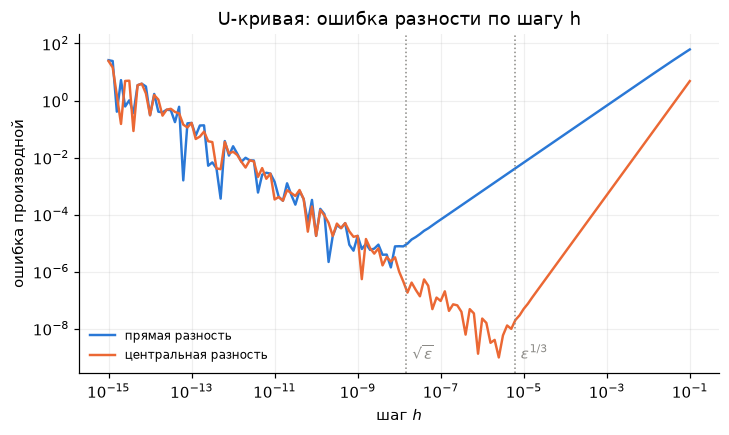

In [3]:
exact = rosen_grad(X0_ROSEN)[0]
ef, ec = ucurve(rosen, X0_ROSEN, 0, exact)                           # ошибки по сетке HS
slope = lambda e, lo, hi: np.polyfit(np.log10(HS[(HS >= lo) & (HS <= hi)]), np.log10(e[(HS >= lo) & (HS <= hi)]), 1)[0]
for name, e, lo in (("прямая", ef, 1e-5), ("центральная", ec, 1e-4)):
    j = np.argmin(e)
    print(f"{name:12s}: лучший h = {HS[j]:.1e}, ошибка {e[j]:.1e};  наклон справа {slope(e, lo, 1e-1):.2f}, слева {slope(e, 1e-15, 1e-10):.2f}")
f11 = 2 - 400 * X0_ROSEN[1] + 1200 * X0_ROSEN[0] ** 2                 # d^2 f / d x1^2 в старте
print(f"формула: h* = 2 sqrt(eps |f| / |f''|) = {2 * np.sqrt(EPS * rosen(X0_ROSEN) / f11):.1e}, ошибка ~ {2 * np.sqrt(EPS * rosen(X0_ROSEN) * f11):.1e}   (в конспекте: 4e-9 и до 5e-6)")
fig, ax = plt.subplots(figsize=(7.5, 4))
ucurve_plot(ax, [ef, ec], ["прямая разность", "центральная разность"], [BLUE, ORANGE])
ax.set(title="U-кривая: ошибка разности по шагу h"); plt.show()

**SciPy без `jac`.** BFGS на Розенброке с точным градиентом и с разностным, который SciPy берёт сам (`jac=None`, прямые разности с шагом `eps = 1.49e-8`): итераций $33$ и $33$, вызовов $f$ — $40$ и $120$, а точный градиент в найденной точке — $10^{-8}$ против $10^{-5}$.

In [4]:
for name, jac in (("точный градиент", rosen_grad), ("jac=None (разности)", None), ("jac='3-point'", "3-point")):
    r = minimize(rosen, X0_ROSEN, jac=jac, method="BFGS", options={"gtol": 1e-6})
    print(f"{name:20s}: итераций {r.nit}, вызовов f {r.nfev:3d}, |grad f(x*)| точный = {np.linalg.norm(rosen_grad(r.x)):.1e}, |x* - (1,1)| = {np.linalg.norm(r.x - 1):.1e}")

точный градиент     : итераций 33, вызовов f  40, |grad f(x*)| точный = 2.6e-08, |x* - (1,1)| = 1.7e-09
jac=None (разности) : итераций 33, вызовов f 120, |grad f(x*)| точный = 6.1e-06, |x* - (1,1)| = 1.0e-05
jac='3-point'       : итераций 33, вызовов f 200, |grad f(x*)| точный = 1.6e-08, |x* - (1,1)| = 1.4e-08


## (b) Алгоритмическое дифференцирование своими руками (разделы 3–4)

**Что проверяем.** Программа $f=x_1x_2+\sin(x_1x_2)$ — три операции в списке `PROGRAM`. Прямой режим по направлению $d=(1,0)$ в точке $(2,0.5)$: $\dot v_1=0.5$, $\dot v_2=0.2702$, $\dot f=0.7702$. Обратный режим: $\bar v_2=1$, $\bar v_1=1.5403$, $\bar x=(0.7702,\ 3.0806)$ — весь градиент за один проход. Код `forward_mode` и `reverse_mode` — в ячейке настройки, по 10 строк каждый.

In [5]:
x = {"x1": 2.0, "x2": 0.5}
val, dot = forward_mode(PROGRAM, x, {"x1": 1.0, "x2": 0.0})            # прямой режим, d = (1, 0)
print("прямой режим, d = (1, 0):", {k: round(v, 4) for k, v in dot.items()})
val, bar = reverse_mode(PROGRAM, x)                                    # обратный режим
print("обратный режим:          ", {k: round(v, 4) for k, v in bar.items()})
g = lambda x1, x2: np.array([x2 * (1 + np.cos(x1 * x2)), x1 * (1 + np.cos(x1 * x2))])
print("градиент по формуле:     ", g(2.0, 0.5).round(4), "  (в конспекте: 0.7702, 3.0806)")
assert np.allclose([bar["x1"], bar["x2"]], g(2.0, 0.5)) and np.isclose(dot["f"], g(2.0, 0.5)[0])

прямой режим, d = (1, 0): {'x1': 1.0, 'x2': 0.0, 'v1': 0.5, 'v2': np.float64(0.2702), 'f': np.float64(0.7702)}
обратный режим:           {'x1': np.float64(0.7702), 'x2': np.float64(3.0806), 'v1': np.float64(1.5403), 'v2': 1.0, 'f': 1.0}
градиент по формуле:      [0.7702 3.0806]   (в конспекте: 0.7702, 3.0806)


**Трасса обратного прохода по шагам** — та же, что в §4.1: $f=v_1+v_2$ раздаёт по единице, $v_2=\sin v_1$ добавляет $v_1$ долю $\cos v_1=0.5403$, $v_1=x_1x_2$ раздаёт входам $\bar v_1x_2$ и $\bar v_1x_1$.

In [6]:
val = dict(x)
for name, op, args in PROGRAM:
    val[name] = OPS[op][0](*[val[k] for k in args])
bar = {k: 0.0 for k in val}; bar["f"] = 1.0
for name, op, args in reversed(PROGRAM):
    a = [val[k] for k in args]
    for p, k in zip(OPS[op][1](*a), args):
        bar[k] += bar[name] * p
        print(f"{name} = {op}{args}: {k} += {bar[name]:.4f} * {p:.4f}  ->  bar {k} = {bar[k]:.4f}")

f = add('v1', 'v2'): v1 += 1.0000 * 1.0000  ->  bar v1 = 1.0000
f = add('v1', 'v2'): v2 += 1.0000 * 1.0000  ->  bar v2 = 1.0000
v2 = sin('v1',): v1 += 1.0000 * 0.5403  ->  bar v1 = 1.5403
v1 = mul('x1', 'x2'): x1 += 1.5403 * 0.5000  ->  bar x1 = 0.7702
v1 = mul('x1', 'x2'): x2 += 1.5403 * 2.0000  ->  bar x2 = 3.0806


**Мини-задание лекции:** та же функция в $(1,\pi)$. $v_1=\pi$, $\bar v_1=1+\cos\pi=0$ — градиент нулевой, точка стационарная.

In [7]:
val, bar = reverse_mode(PROGRAM, {"x1": 1.0, "x2": np.pi})
print(f"в (1, pi): v1 = {val['v1']:.4f}, bar v1 = {bar['v1']:.1e}, градиент = ({bar['x1']:.1e}, {bar['x2']:.1e})")

в (1, pi): v1 = 3.1416, bar v1 = 0.0e+00, градиент = (0.0e+00, 0.0e+00)


## (c) CasADi на упругой цепи (раздел 5)

**Что проверяем.** Энергия цепи как граф CasADi (цикл по пружинам, `chain_casadi`). Число операций `n_instructions()`: градиент $\times1.6$, гессиан $\times5.5$–$5.7$, гессиан на вектор через `jtimes` $\times3.3$ — при $N=40$, $200$, $1000$; ненулевых в гессиане $472$ из $6400$ при $N=40$. IPOPT из прямой: $24$ итерации с точным гессианом против $232$ с L-BFGS.

In [8]:
print(f"{'N':>5s} {'n':>5s} {'E':>7s} {'grad':>7s} {'hess':>7s} {'H d':>7s}   ненулевых в гессиане")
for N in (40, 200, 1000):
    nf, ng, nh, nhd, nnz = chain_costs(N)
    print(f"{N:5d} {2 * N:5d} {nf:7d} {ng:7d} {nh:7d} {nhd:7d}   {nnz} из {(2 * N) ** 2} = {100 * nnz / (2 * N) ** 2:.1f} %   (x{ng / nf:.2f}, x{nh / nf:.1f}, x{nhd / nf:.1f})")
print("в конспекте: x1.6, x5.5-5.7, x3.3; 472 из 6400")

    N     n       E    grad    hess     H d   ненулевых в гессиане
   40    80     537     860    2968    1759   472 из 6400 = 7.4 %   (x1.60, x5.5, x3.3)
  200   400    2617    4220   14836    8639   2392 из 160000 = 1.5 %   (x1.61, x5.7, x3.3)


 1000  2000   13017   21020   74168   43039   11992 из 4000000 = 0.3 %   (x1.61, x5.7, x3.3)
в конспекте: x1.6, x5.5-5.7, x3.3; 472 из 6400


**Портрет гессиана.** Пружина связывает двух соседей, отсюда четыре трёхдиагональные ленты (блоки $y$–$y$, $y$–$z$, $z$–$y$, $z$–$z$). CasADi находит эти ленты по графу до всяких вычислений.

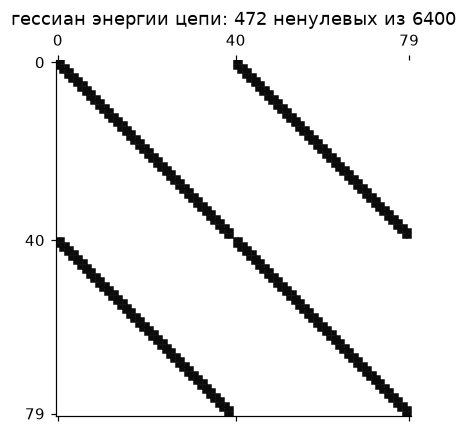

In [9]:
pattern, v_star, Hfun = chain_pattern(40)                            # структура из графа и равновесие цепи
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.spy(pattern, markersize=2.5, color=INK); ax.grid(False)
ax.set(title=f"гессиан энергии цепи: {int(pattern.sum())} ненулевых из 6400", xticks=[0, 40, 79], yticks=[0, 40, 79]); plt.show()

**Что даёт солверу точный гессиан.** IPOPT на той же цепи из прямой: `hessian_approximation="exact"` — гессиан от CasADi, `"limited-memory"` — L-BFGS внутри IPOPT.

In [10]:
v, E = chain_casadi(40); v0 = make_elastic_chain(40)[2]                     # старт — прямая между концами
for mode in ("exact", "limited-memory"):
    solver = ca.nlpsol("s", "ipopt", {"x": v, "f": E}, {"ipopt.hessian_approximation": mode, "ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes", "ipopt.tol": 1e-8})
    sol = solver(x0=v0); st = solver.stats()
    print(f"hessian_approximation = {mode:15s}: итераций {st['iter_count']:3d}, E* = {float(sol['f']):.4f}, {st['return_status']}")
print("в конспекте: 24 против 232")

hessian_approximation = exact          : итераций  24, E* = -44.5388, Solve_Succeeded


hessian_approximation = limited-memory : итераций 232, E* = -44.5388, Solve_Succeeded
в конспекте: 24 против 232


## (e) Подробности

**Мнимый трюк (упражнение 7.4).** $f'(x)\approx\operatorname{Im}f(x+ih)/h$: вычитания нет, при $h=10^{-20}$ ошибка на уровне $10^{-14}$ при производной $-215.6$.

In [11]:
h = 1e-20
z = X0_ROSEN.astype(complex); z[0] += 1j * h
print(f"мнимый трюк: ошибка {abs(np.imag(rosen(z)) / h - rosen_grad(X0_ROSEN)[0]):.1e};  прямая разность при лучшем h: 1.4e-6")

мнимый трюк: ошибка 2.8e-14;  прямая разность при лучшем h: 1.4e-6


**Разности от шумной функции (вопрос залу §2.4).** $f$ с относительным шумом $10^{-10}$: левая ветка поднимается на шесть порядков, дно уезжает к $h\sim10^{-6}$ (прямая) и $10^{-4}$ (центральная), ошибки $4\cdot10^{-4}$ и $10^{-6}$.

шумная f, прямая      : лучший h = 1.6e-06, ошибка 4.1e-04
шумная f, центральная : лучший h = 1.3e-04, ошибка 1.4e-06


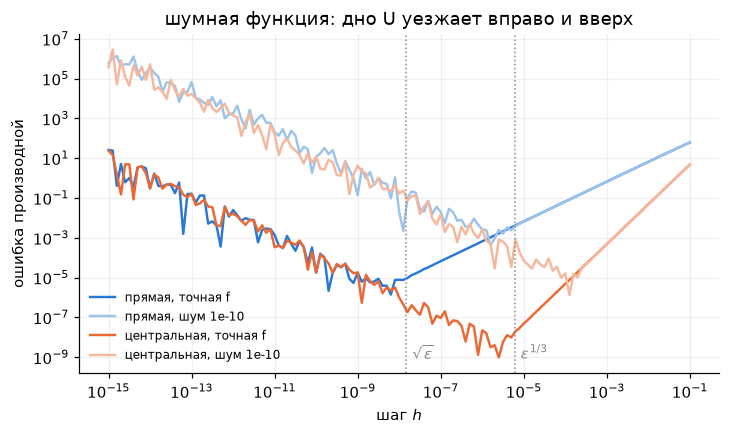

In [12]:
rng = np.random.default_rng(0)
noisy = lambda x: rosen(x) * (1 + 1e-10 * rng.standard_normal())
exact = rosen_grad(X0_ROSEN)[0]; ef, ec = ucurve(rosen, X0_ROSEN, 0, exact)
efn, ecn = ucurve(noisy, X0_ROSEN, 0, exact)
for name, e in (("прямая", efn), ("центральная", ecn)):
    j = np.argmin(e); print(f"шумная f, {name:12s}: лучший h = {HS[j]:.1e}, ошибка {e[j]:.1e}")
fig, ax = plt.subplots(figsize=(7.5, 4))
ucurve_plot(ax, [ef, efn, ec, ecn], ["прямая, точная f", "прямая, шум 1e-10", "центральная, точная f", "центральная, шум 1e-10"], [BLUE, "#9dc3ea", ORANGE, "#f5b89d"])
ax.set(title="шумная функция: дно U уезжает вправо и вверх"); plt.show()

**Разностный гессиан цепи** по значениям энергии в равновесии: $25\,600$ вычислений, ошибка до $3\cdot10^{-5}$ и шум вместо нулей между лентами.

ошибка разностного гессиана: 2.7e-05; «ненулевых» 3996 вместо 472


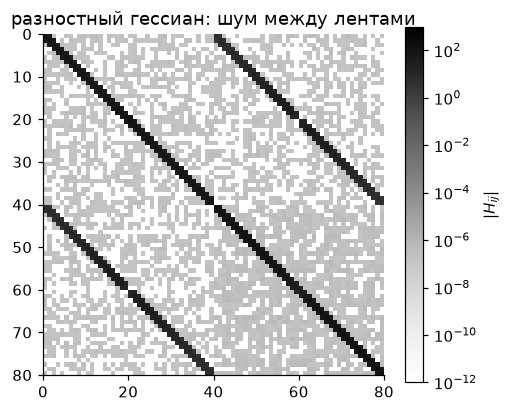

In [13]:
n, hh = 80, 1e-4
energy = make_elastic_chain(40)[0]
H = np.array(Hfun(v_star)); I = np.eye(n); Hff = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        ei, ej = I[i], I[j]
        Hff[i, j] = (energy(v_star + hh * (ei + ej)) - energy(v_star + hh * (ei - ej)) - energy(v_star - hh * (ei - ej)) + energy(v_star - hh * (ei + ej))) / (4 * hh * hh)
print(f"ошибка разностного гессиана: {np.abs(Hff - H).max():.1e}; «ненулевых» {int(np.sum(np.abs(Hff) > 1e-12))} вместо 472")
fig, ax = plt.subplots(figsize=(5, 4.2))
pc = ax.pcolormesh(np.maximum(np.abs(Hff), 1e-12), cmap="Greys", norm=LogNorm(vmin=1e-12, vmax=1e3)); ax.invert_yaxis(); ax.grid(False)
ax.set(aspect="equal", title="разностный гессиан: шум между лентами"); fig.colorbar(pc, ax=ax, label="$|H_{ij}|$"); plt.show()

**Время при $n=2000$.** Градиент разностями по numpy-энергии против градиента CasADi: сотни миллисекунд против долей миллисекунды. При малых $n$ разница меньше — накладные расходы вызова `Function` сравнимы с самим счётом.

In [14]:
energy1000, grad1000, v1000 = make_elastic_chain(1000)
v, E = chain_casadi(1000); G = ca.Function("G", [v], [ca.gradient(E, v)])
t0 = time.perf_counter(); [fd_forward(energy1000, v1000, i, 1e-8) for i in range(2000)]; t_fd = time.perf_counter() - t0
t0 = time.perf_counter(); [G(v1000) for _ in range(50)]; t_ad = (time.perf_counter() - t0) / 50
print(f"n = 2000: градиент разностями {t_fd * 1e3:.0f} мс, CasADi {t_ad * 1e3:.2f} мс — в {t_fd / t_ad:.0f} раз")

n = 2000: градиент разностями 114 мс, CasADi 0.19 мс — в 605 раз


## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| прямая разность | $\dfrac{f(x+he_i)-f(x)}{h}$, ошибка $\tfrac h2\lvert f''\rvert+\tfrac{2\varepsilon\lvert f\rvert}{h}$ | §2.1 |
| лучший шаг | $h^\ast=2\sqrt{\varepsilon\lvert f\rvert/\lvert f''\rvert}\sim\sqrt\varepsilon$, ошибка $\sim\sqrt\varepsilon$ | §2.1 |
| центральная разность | $\dfrac{f(x+he_i)-f(x-he_i)}{2h}$, $h^\ast\sim\varepsilon^{1/3}$, ошибка $\sim\varepsilon^{2/3}$ | §2.2 |
| прямой режим | $\dot v_i=\sum_j\frac{\partial\varphi_i}{\partial v_j}\dot v_j$, на выходе $\nabla f^\top d$ | §3.2 |
| обратный режим | $\bar v_j\mathrel{+}=\bar v_i\,\partial\varphi_i/\partial v_j$, на выходе $\bar x=\nabla f$ | §4.2 |
| цена | вперёд $\le2.5$ цены $f$ на направление; назад $\le4$ на весь градиент | §3.3, §4 |
| CasADi | `gradient` — назад, `jtimes` — вперёд, `hessian` — назад по прямому, `n_instructions()` — цена | §5 |

**Три вещи, которые легко перепутать.**

1. $\dot v_i$ — производная $v_i$ по направлению $d$ (считается вместе с $v_i$); $\bar v_i$ — производная $f$ по $v_i$ (считается после, от выхода).
2. Ошибка округления — не ошибка формулы: формула точна в пределе $h\to0$, а числа — нет.
3. `n_instructions()` — число операций, а не время: при малых $n$ вызов `Function` дороже самого счёта.